# importing and data exploring + EDA + feature scaling + enoding

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("kidney_disease.csv")

In [3]:
df.drop("id",axis=1,inplace=True)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             391 non-null    float64
 1   bp              388 non-null    float64
 2   sg              353 non-null    float64
 3   al              354 non-null    float64
 4   su              351 non-null    float64
 5   rbc             248 non-null    str    
 6   pc              335 non-null    str    
 7   pcc             396 non-null    str    
 8   ba              396 non-null    str    
 9   bgr             356 non-null    float64
 10  bu              381 non-null    float64
 11  sc              383 non-null    float64
 12  sod             313 non-null    float64
 13  pot             312 non-null    float64
 14  hemo            348 non-null    float64
 15  pcv             330 non-null    str    
 16  wc              295 non-null    str    
 17  rc              270 non-null    str    
 18  h

In [5]:
all_columns = ['id', 'age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr',
       'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc', 'htn', 'dm', 'cad',
       'appet', 'pe', 'ane', 'classification', 'pcvb']

In [6]:
df.isnull().sum()

age                 9
bp                 12
sg                 47
al                 46
su                 49
rbc               152
pc                 65
pcc                 4
ba                  4
bgr                44
bu                 19
sc                 17
sod                87
pot                88
hemo               52
pcv                70
wc                105
rc                130
htn                 2
dm                  2
cad                 2
appet               1
pe                  1
ane                 1
classification      0
dtype: int64

In [7]:
df.describe()

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo
count,391.000000,388.000000,353.000000,354.000000,351.000000,356.000000,381.000000,383.000000,313.000000,312.000000,348.000000
mean,51.483376,76.469072,1.017408,1.016949,0.450142,148.036517,57.425722,3.072454,137.528754,4.627244,12.526437
std,17.169714,13.683637,0.005717,1.352679,1.099191,79.281714,50.503006,5.741126,10.408752,3.193904,2.912587
min,2.000000,50.000000,1.005000,0.000000,0.000000,22.000000,1.500000,0.400000,4.500000,2.500000,3.100000
25%,42.000000,70.000000,1.010000,0.000000,0.000000,99.000000,27.000000,0.900000,135.000000,3.800000,10.300000
50%,55.000000,80.000000,1.020000,0.000000,0.000000,121.000000,42.000000,1.300000,138.000000,4.400000,12.650000
75%,64.500000,80.000000,1.020000,2.000000,0.000000,163.000000,66.000000,2.800000,142.000000,4.900000,15.000000
max,90.000000,180.000000,1.025000,5.000000,5.000000,490.000000,391.000000,76.000000,163.000000,47.000000,17.800000


In [8]:
df["classification"].value_counts()

classification
ckd       248
notckd    150
ckd\t       2
Name: count, dtype: int64

In [9]:
df.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [10]:
# handling null values 
nums_cols = df.select_dtypes(include=np.number).columns
categ_cols = df.select_dtypes(include="object").columns

for cols in nums_cols:
    df[cols] = df[cols].fillna(df[cols].mean())
for cols in categ_cols:
    df[cols] = df[cols].fillna(df[cols].mode()[0])

In [11]:
df.isnull().sum()

age               0
bp                0
sg                0
al                0
su                0
rbc               0
pc                0
pcc               0
ba                0
bgr               0
bu                0
sc                0
sod               0
pot               0
hemo              0
pcv               0
wc                0
rc                0
htn               0
dm                0
cad               0
appet             0
pe                0
ane               0
classification    0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df['classification'] = df['classification'].str.strip()
df['cad'] = df['cad'].str.strip()
df['dm'] = df['dm'].str.strip()
df['pcv'] = df['pcv'].str.strip()

In [14]:
df["classification"].value_counts()

classification
ckd       250
notckd    150
Name: count, dtype: int64

In [15]:
categ_columns = ['rbc', 'pc', 'pcc', 'ba', 'pcv', 'wc', 'rc', 'htn', 'dm', 'cad',
       'appet', 'pe', 'ane', 'classification']

In [16]:
#convert str to int 
df['wc'] = pd.to_numeric(df['wc'], errors='coerce')
df['rc'] = pd.to_numeric(df['rc'], errors='coerce')
df['pcv'] = pd.to_numeric(df['pcv'], errors='coerce')

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             400 non-null    float64
 1   bp              400 non-null    float64
 2   sg              400 non-null    float64
 3   al              400 non-null    float64
 4   su              400 non-null    float64
 5   rbc             400 non-null    str    
 6   pc              400 non-null    str    
 7   pcc             400 non-null    str    
 8   ba              400 non-null    str    
 9   bgr             400 non-null    float64
 10  bu              400 non-null    float64
 11  sc              400 non-null    float64
 12  sod             400 non-null    float64
 13  pot             400 non-null    float64
 14  hemo            400 non-null    float64
 15  pcv             399 non-null    float64
 16  wc              399 non-null    float64
 17  rc              399 non-null    float64
 18  h

In [18]:
df.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,48.0,80.0,1.020,1.0,0.0,normal,normal,notpresent,notpresent,121.000000,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,normal,normal,notpresent,notpresent,148.036517,...,38.0,6000.0,5.2,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.000000,...,31.0,7500.0,5.2,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.000000,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.000000,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


In [19]:
#encoding the data
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)
# handling null values 
nums_cols = df_encoded.select_dtypes(include=np.number).columns
categ_cols = df_encoded.select_dtypes(include="object").columns

for cols in nums_cols:
    df_encoded[cols] = df_encoded[cols].fillna(df_encoded[cols].mean())
for cols in categ_cols:
    df_encoded[cols] = df_encoded[cols].fillna(df_encoded[cols].mode()[0])

In [20]:
df_encoded.columns

Index(['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo',
       'pcv', 'wc', 'rc', 'rbc_normal', 'pc_normal', 'pcc_present',
       'ba_present', 'htn_yes', 'dm_yes', 'cad_yes', 'appet_poor', 'pe_yes',
       'ane_yes', 'classification_notckd'],
      dtype='str')

In [21]:
# # scaling the data
# specific_cols = ['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo',
#        'pcv', 'wc', 'rc', 'rbc_normal', 'pc_normal', 'pcc_present',
#        'ba_present', 'htn_yes', 'dm_yes', 'cad_yes', 'appet_poor', 'pe_yes',
#        'ane_yes']
# scale =StandardScaler()
# df_encoded[specific_cols] = scale.fit_transform(df_encoded[specific_cols])

# visualization

<Axes: >

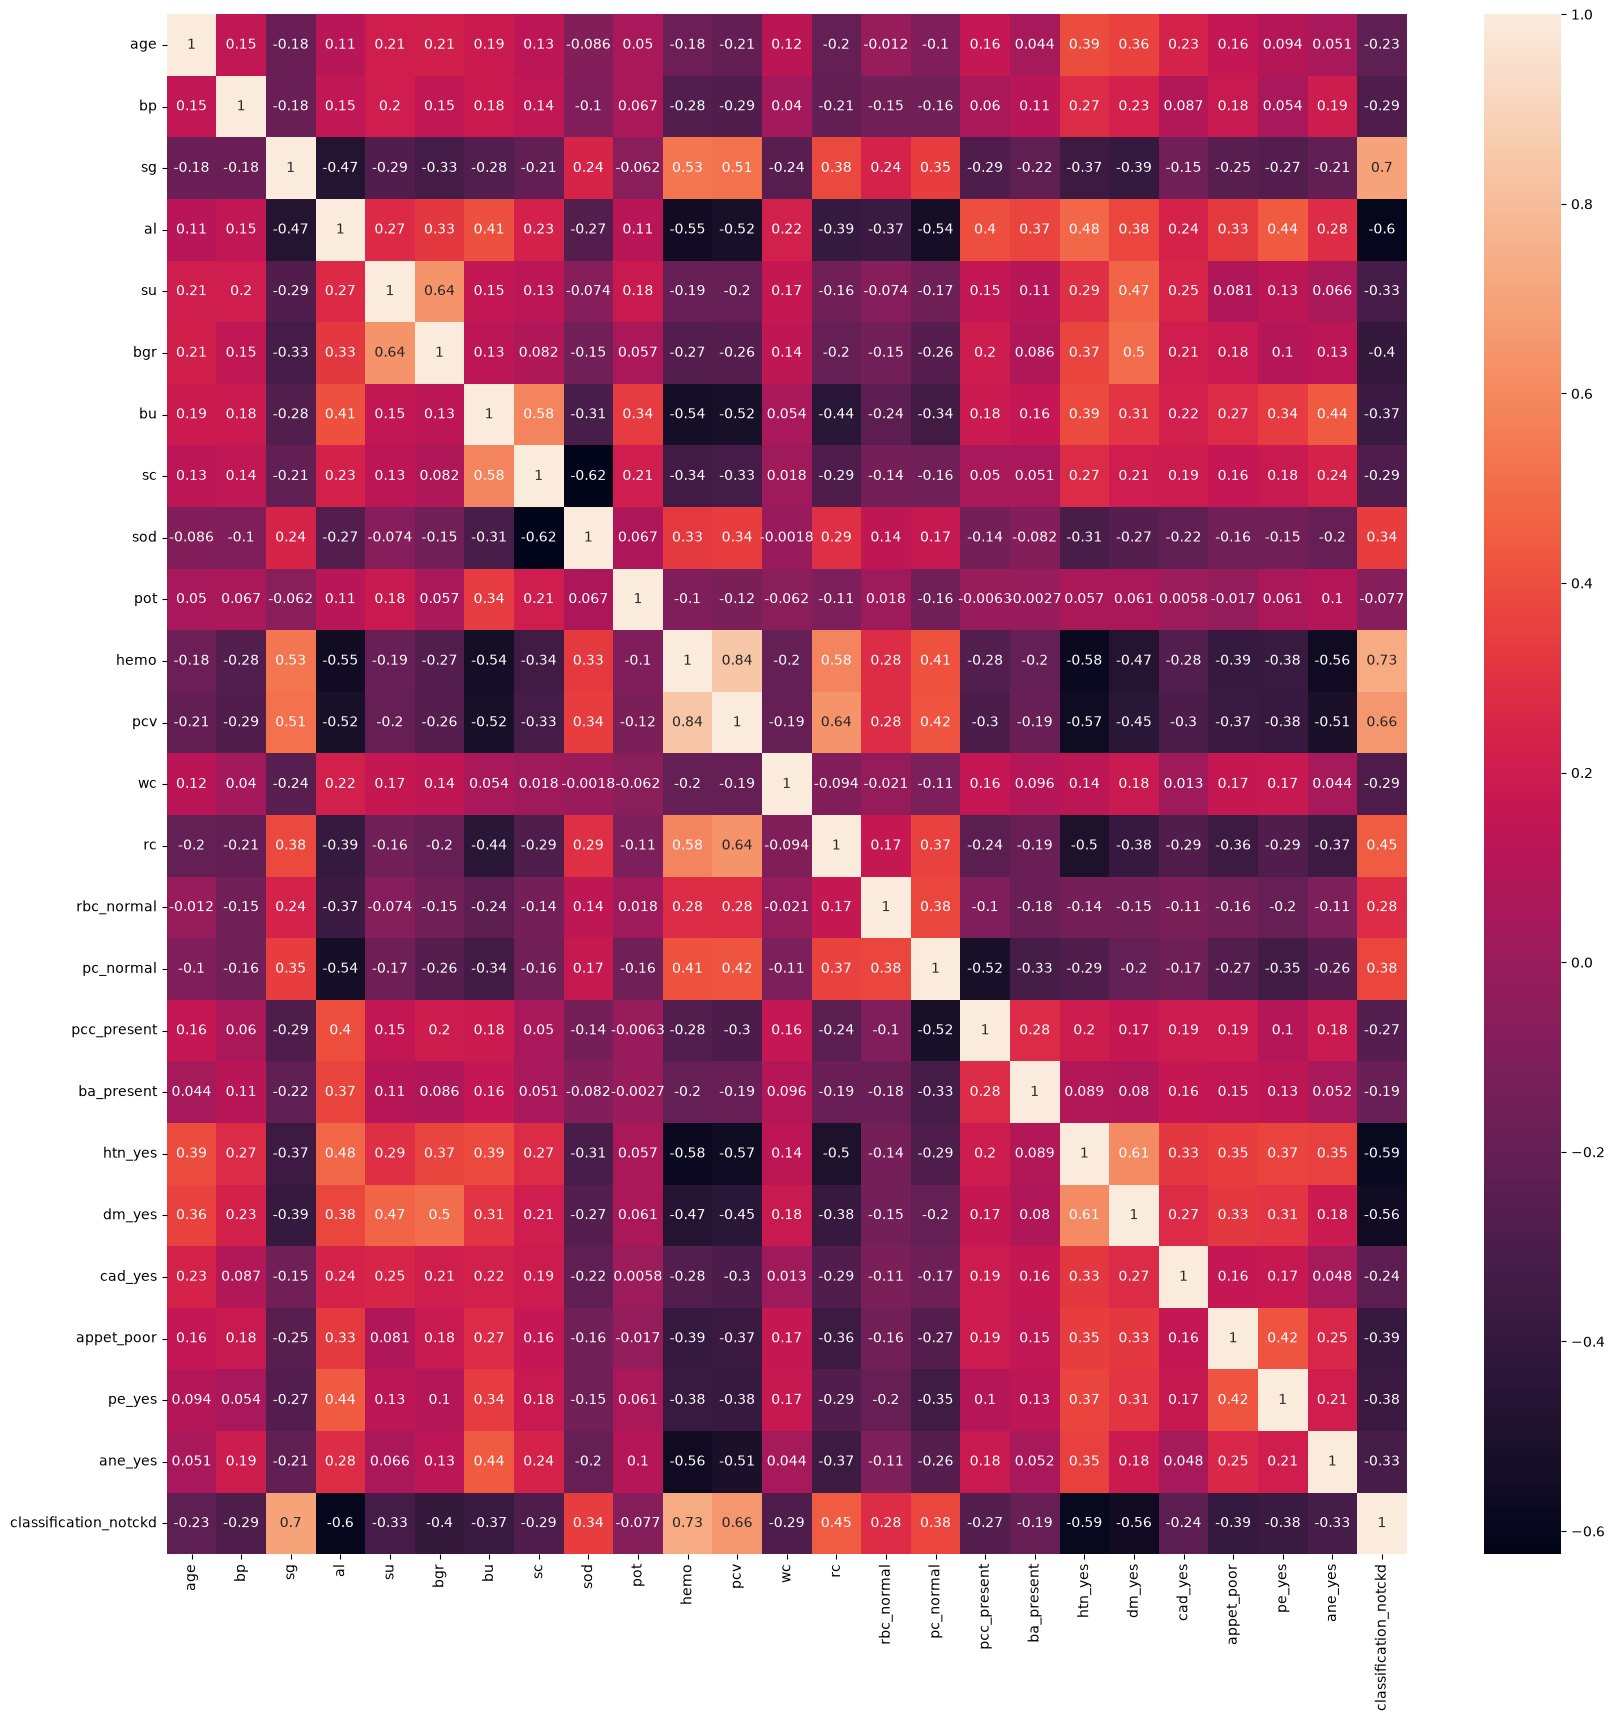

In [22]:
plt.figure(figsize=[20,20])
sns.heatmap(df_encoded.corr(),annot=True)

# model training : 

In [23]:
X = df_encoded.drop("classification_notckd", axis = 1)
y = df_encoded["classification_notckd"]

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [25]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

# Logistic Regression Model

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,precision_score,recall_score,f1_score
import warnings
warnings.filterwarnings("ignore")

In [27]:
model_lr = LogisticRegression(solver= 'lbfgs', C= 1)

In [28]:
model_lr.fit(X_train_scaled,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solve

In [29]:
y_predection_lr = model_lr.predict(X_test_scaled)

In [30]:
print("accuracy score of lr : \n",accuracy_score(y_test,y_predection_lr))
print("classification report of lr : \n",classification_report(y_test,y_predection_lr))
print("confusion matrix of lr : \n",confusion_matrix(y_test,y_predection_lr))
print("precision score of lr : \n",precision_score(y_test,y_predection_lr))
print("recall score of lr : \n",recall_score(y_test,y_predection_lr))
print("f1 score of lr : \n",f1_score(y_test,y_predection_lr))

accuracy score of lr : 
 0.9924242424242424
classification report of lr : 
               precision    recall  f1-score   support

           0       1.00      0.99      0.99        84
           1       0.98      1.00      0.99        48

    accuracy                           0.99       132
   macro avg       0.99      0.99      0.99       132
weighted avg       0.99      0.99      0.99       132

confusion matrix of lr : 
 [[83  1]
 [ 0 48]]
precision score of lr : 
 0.9795918367346939
recall score of lr : 
 1.0
f1 score of lr : 
 0.9896907216494846


# KNN 

In [31]:
from sklearn.neighbors import KNeighborsClassifier

In [32]:
model_knn = KNeighborsClassifier()

In [33]:
model_knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [34]:
y_predection_knn = model_knn.predict(X_test_scaled)

In [35]:
print("accuracy score knn : \n",accuracy_score(y_test,y_predection_knn))
print("classification report knn : \n",classification_report(y_test,y_predection_knn))
print("confusion matrix knn : \n",confusion_matrix(y_test,y_predection_knn))
print("precision score knn : \n",precision_score(y_test,y_predection_knn))
print("recall score knn : \n",recall_score(y_test,y_predection_knn))
print("f1 score knn : \n",f1_score(y_test,y_predection_knn))

accuracy score knn : 
 0.9621212121212122
classification report knn : 
               precision    recall  f1-score   support

           0       1.00      0.94      0.97        84
           1       0.91      1.00      0.95        48

    accuracy                           0.96       132
   macro avg       0.95      0.97      0.96       132
weighted avg       0.97      0.96      0.96       132

confusion matrix knn : 
 [[79  5]
 [ 0 48]]
precision score knn : 
 0.9056603773584906
recall score knn : 
 1.0
f1 score knn : 
 0.9504950495049505


# naive bayes model 

In [36]:
from sklearn.naive_bayes import GaussianNB

In [37]:
model_nb = GaussianNB()

In [38]:
model_nb.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[166.,102.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.62,0.38]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,0.007304
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](24,)","['age','bp','sg',...,'appet_poor','pe_yes','ane_yes']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,24
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 24)","[[55.11,79.07, 1.01,..., 0.34, 0.3 , 0.23], [46.01,71.3 , 1.02,..., 0. , 0. , 0. ]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 24)","[[307.28,247.25, 0.01,..., 0.23, 0.22, 0.19], [253.78, 71.68, 0.01,..., 0.01, 0.01, 0.01]]"


In [39]:
y_predection_nb = model_nb.predict(X_test)

In [40]:
print("accuracy score naive bayes : \n",accuracy_score(y_test,y_predection_nb))
print("classification report naive bayes : \n",classification_report(y_test,y_predection_nb))
print("confusion matrix naive bayes : \n",confusion_matrix(y_test,y_predection_nb))
print("precision score naive bayes : \n",precision_score(y_test,y_predection_nb))
print("recall score naive bayes : \n",recall_score(y_test,y_predection_nb))
print("f1 score naive bayes : \n",f1_score(y_test,y_predection_nb))

accuracy score naive bayes : 
 0.9696969696969697
classification report naive bayes : 
               precision    recall  f1-score   support

           0       1.00      0.95      0.98        84
           1       0.92      1.00      0.96        48

    accuracy                           0.97       132
   macro avg       0.96      0.98      0.97       132
weighted avg       0.97      0.97      0.97       132

confusion matrix naive bayes : 
 [[80  4]
 [ 0 48]]
precision score naive bayes : 
 0.9230769230769231
recall score naive bayes : 
 1.0
f1 score naive bayes : 
 0.96


# decision tree model

In [41]:
from sklearn.tree import DecisionTreeClassifier

In [42]:
model_dt = DecisionTreeClassifier()

In [43]:
model_dt.fit(X_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [44]:
y_predection_dt = model_dt.predict(X_test)

In [45]:
print("accuracy score decision tree : \n",accuracy_score(y_test,y_predection_dt))
print("classification report decision tree : \n",classification_report(y_test,y_predection_dt))
print("confusion matrix decision tree : \n",confusion_matrix(y_test,y_predection_dt))
print("precision score decision tree : \n",precision_score(y_test,y_predection_dt))
print("recall score decision tree : \n",recall_score(y_test,y_predection_dt))
print("f1 score decision tree : \n",f1_score(y_test,y_predection_dt))

accuracy score decision tree : 
 0.9848484848484849
classification report decision tree : 
               precision    recall  f1-score   support

           0       1.00      0.98      0.99        84
           1       0.96      1.00      0.98        48

    accuracy                           0.98       132
   macro avg       0.98      0.99      0.98       132
weighted avg       0.99      0.98      0.98       132

confusion matrix decision tree : 
 [[82  2]
 [ 0 48]]
precision score decision tree : 
 0.96
recall score decision tree : 
 1.0
f1 score decision tree : 
 0.9795918367346939


# support vector machine 

In [46]:
from sklearn.svm import SVC

In [47]:
model_svm = SVC(kernel="rbf")

In [48]:
model_svm.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [49]:
y_predection_svm = model_svm.predict(X_test)

In [50]:
print("accuracy score svm : \n",accuracy_score(y_test,y_predection_svm))
print("classification report svm : \n",classification_report(y_test,y_predection_svm))
print("confusion matrix svm : \n",confusion_matrix(y_test,y_predection_svm))
print("precision score svm : \n",precision_score(y_test,y_predection_svm))
print("recall score svm : \n",recall_score(y_test,y_predection_svm))
print("f1 score svm : \n",f1_score(y_test,y_predection_svm))

accuracy score svm : 
 0.6212121212121212
classification report svm : 
               precision    recall  f1-score   support

           0       0.68      0.75      0.72        84
           1       0.47      0.40      0.43        48

    accuracy                           0.62       132
   macro avg       0.58      0.57      0.57       132
weighted avg       0.61      0.62      0.61       132

confusion matrix svm : 
 [[63 21]
 [29 19]]
precision score svm : 
 0.475
recall score svm : 
 0.3958333333333333
f1 score svm : 
 0.4318181818181818


# Random Forest Model

In [51]:
from sklearn.ensemble import RandomForestClassifier

In [52]:
rf_model = RandomForestClassifier(
    random_state=42,
    n_estimators= 300, min_samples_split= 2, min_samples_leaf= 1, max_depth= 15
)

In [53]:
rf_model.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

In [54]:
y_predection_rf = rf_model.predict(X_test)

In [55]:
print("accuracy score random forest : \n",accuracy_score(y_test,y_predection_rf))
print("classification report random forest : \n",classification_report(y_test,y_predection_rf))
print("confusion matrix random forest : \n",confusion_matrix(y_test,y_predection_rf))
print("precision score random forest : \n",precision_score(y_test,y_predection_rf))
print("recall score random forest : \n",recall_score(y_test,y_predection_rf))
print("f1 score random forest : \n",f1_score(y_test,y_predection_rf))

accuracy score random forest : 
 0.9924242424242424
classification report random forest : 
               precision    recall  f1-score   support

           0       1.00      0.99      0.99        84
           1       0.98      1.00      0.99        48

    accuracy                           0.99       132
   macro avg       0.99      0.99      0.99       132
weighted avg       0.99      0.99      0.99       132

confusion matrix random forest : 
 [[83  1]
 [ 0 48]]
precision score random forest : 
 0.9795918367346939
recall score random forest : 
 1.0
f1 score random forest : 
 0.9896907216494846


# XGboost model 

In [56]:
from xgboost import XGBClassifier

In [57]:
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    eval_metric="logloss"
)

In [58]:
xgb_model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [59]:
y_predection_xgb = xgb_model.predict(X_test)

In [60]:
print("accuracy score xgboosting : \n",accuracy_score(y_test,y_predection_xgb))
print("classification report xgboosting : \n",classification_report(y_test,y_predection_xgb))
print("confusion matrix xgboosting : \n",confusion_matrix(y_test,y_predection_xgb))
print("precision score xgboosting : \n",precision_score(y_test,y_predection_xgb))
print("recall score xgboosting : \n",recall_score(y_test,y_predection_xgb))
print("f1 score xgboosting : \n",f1_score(y_test,y_predection_xgb))

accuracy score xgboosting : 
 0.9848484848484849
classification report xgboosting : 
               precision    recall  f1-score   support

           0       1.00      0.98      0.99        84
           1       0.96      1.00      0.98        48

    accuracy                           0.98       132
   macro avg       0.98      0.99      0.98       132
weighted avg       0.99      0.98      0.98       132

confusion matrix xgboosting : 
 [[82  2]
 [ 0 48]]
precision score xgboosting : 
 0.96
recall score xgboosting : 
 1.0
f1 score xgboosting : 
 0.9795918367346939


# results of all 7 models : 

In [61]:
print("accuracy score of lr : \n",accuracy_score(y_test,y_predection_lr))
print("classification report of lr : \n",classification_report(y_test,y_predection_lr))
print("confusion matrix of lr : \n",confusion_matrix(y_test,y_predection_lr))
print("precision score of lr : \n",precision_score(y_test,y_predection_lr))
print("recall score of lr : \n",recall_score(y_test,y_predection_lr))
print("f1 score of lr : \n",f1_score(y_test,y_predection_lr))


print("accuracy score knn : \n",accuracy_score(y_test,y_predection_knn))
print("classification report knn : \n",classification_report(y_test,y_predection_knn))
print("confusion matrix knn : \n",confusion_matrix(y_test,y_predection_knn))
print("precision score knn : \n",precision_score(y_test,y_predection_knn))
print("recall score knn : \n",recall_score(y_test,y_predection_knn))
print("f1 score knn : \n",f1_score(y_test,y_predection_knn))


print("accuracy score naive bayes : \n",accuracy_score(y_test,y_predection_nb))
print("classification report naive bayes : \n",classification_report(y_test,y_predection_nb))
print("confusion matrix naive bayes : \n",confusion_matrix(y_test,y_predection_nb))
print("precision score naive bayes : \n",precision_score(y_test,y_predection_nb))
print("recall score naive bayes : \n",recall_score(y_test,y_predection_nb))
print("f1 score naive bayes : \n",f1_score(y_test,y_predection_nb))


print("accuracy score decision tree : \n",accuracy_score(y_test,y_predection_dt))
print("classification report decision tree : \n",classification_report(y_test,y_predection_dt))
print("confusion matrix decision tree : \n",confusion_matrix(y_test,y_predection_dt))
print("precision score decision tree : \n",precision_score(y_test,y_predection_dt))
print("recall score decision tree : \n",recall_score(y_test,y_predection_dt))
print("f1 score decision tree : \n",f1_score(y_test,y_predection_dt))


print("accuracy score svm : \n",accuracy_score(y_test,y_predection_svm))
print("classification report svm : \n",classification_report(y_test,y_predection_svm))
print("confusion matrix svm : \n",confusion_matrix(y_test,y_predection_svm))
print("precision score svm : \n",precision_score(y_test,y_predection_svm))
print("recall score svm : \n",recall_score(y_test,y_predection_svm))
print("f1 score svm : \n",f1_score(y_test,y_predection_svm))


print("accuracy score random forest : \n",accuracy_score(y_test,y_predection_rf))
print("classification report random forest : \n",classification_report(y_test,y_predection_rf))
print("confusion matrix random forest : \n",confusion_matrix(y_test,y_predection_rf))
print("precision score random forest : \n",precision_score(y_test,y_predection_rf))
print("recall score random forest : \n",recall_score(y_test,y_predection_rf))
print("f1 score random forest : \n",f1_score(y_test,y_predection_rf))


print("accuracy score xgboosting : \n",accuracy_score(y_test,y_predection_xgb))
print("classification report xgboosting : \n",classification_report(y_test,y_predection_xgb))
print("confusion matrix xgboosting : \n",confusion_matrix(y_test,y_predection_xgb))
print("precision score xgboosting : \n",precision_score(y_test,y_predection_xgb))
print("recall score xgboosting : \n",recall_score(y_test,y_predection_xgb))
print("f1 score xgboosting : \n",f1_score(y_test,y_predection_xgb))

accuracy score of lr : 
 0.9924242424242424
classification report of lr : 
               precision    recall  f1-score   support

           0       1.00      0.99      0.99        84
           1       0.98      1.00      0.99        48

    accuracy                           0.99       132
   macro avg       0.99      0.99      0.99       132
weighted avg       0.99      0.99      0.99       132

confusion matrix of lr : 
 [[83  1]
 [ 0 48]]
precision score of lr : 
 0.9795918367346939
recall score of lr : 
 1.0
f1 score of lr : 
 0.9896907216494846
accuracy score knn : 
 0.9621212121212122
classification report knn : 
               precision    recall  f1-score   support

           0       1.00      0.94      0.97        84
           1       0.91      1.00      0.95        48

    accuracy                           0.96       132
   macro avg       0.95      0.97      0.96       132
weighted avg       0.97      0.96      0.96       132

confusion matrix knn : 
 [[79  5]
 [ 0 48]

In [62]:
df_encoded["classification_notckd"].value_counts()

classification_notckd
0    250
1    150
Name: count, dtype: int64

# cross validation : 

In [63]:
# for logistic regression model

In [64]:
from sklearn.model_selection import cross_val_score

In [65]:
scores = cross_val_score(model_lr, X_train_scaled, y_train, cv=10, scoring="accuracy")

In [66]:
print("cross val score for lr ",scores)

cross val score for lr  [1.         1.         1.         1.         0.96296296 1.
 1.         1.         1.         0.96153846]


In [67]:
# for decision tree model

In [68]:
scores_dt = cross_val_score(model_dt, X_train, y_train, cv=10, scoring="accuracy")

In [69]:
print("cross val score for dt ",scores_dt)

cross val score for dt  [0.96296296 1.         0.96296296 0.92592593 0.96296296 1.
 0.85185185 0.88888889 0.92307692 0.88461538]


In [70]:
# for random forest model

In [71]:
scores_rf = cross_val_score(rf_model, X_train, y_train, cv=10, scoring="accuracy")

In [72]:
print("cross val score for rf ",scores_rf)

cross val score for rf  [1.         1.         0.96296296 1.         1.         1.
 0.92592593 1.         0.96153846 1.        ]


# hyperparameter tuning grid search cv

In [73]:
# for logistic regression model 

In [74]:
from sklearn.model_selection import RandomizedSearchCV

In [75]:
classifier_random_lr = RandomizedSearchCV((model_lr), {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs']
    
},n_iter=10,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    random_state=42)

In [76]:
classifier_random_lr.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegression(C=1)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'C': [0.01, 0.1, ...], 'solver': ['liblinear', 'lbfgs']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``bes

In [77]:
print(classifier_random_lr.best_params_)
print(classifier_random_lr.best_score_)

{'solver': 'lbfgs', 'C': 1}
0.9765018305574177


In [78]:
# for random search cv 

In [79]:
classifier_random_rf = RandomizedSearchCV((rf_model), {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
    
},n_iter=10,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    random_state=42)

In [80]:
classifier_random_rf.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [None, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multi

In [81]:
print(classifier_random_rf.best_params_)
print(classifier_random_rf.best_score_)

{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 15}
0.9796943162916234


# ROC - AUC 

In [82]:
from sklearn.metrics import roc_curve, roc_auc_score

In [86]:
y_prob_lr = classifier_random_lr.best_estimator_.predict_proba(X_test_scaled)[:, 1]

y_prob_rf = classifier_random_rf.best_estimator_.predict_proba(X_test)[:, 1]

In [87]:
auc_lr = roc_auc_score(y_test, y_prob_lr)

auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Logistic Regression AUC:", auc_lr)
print("Random Forest AUC:", auc_rf)

Logistic Regression AUC: 1.0
Random Forest AUC: 1.0


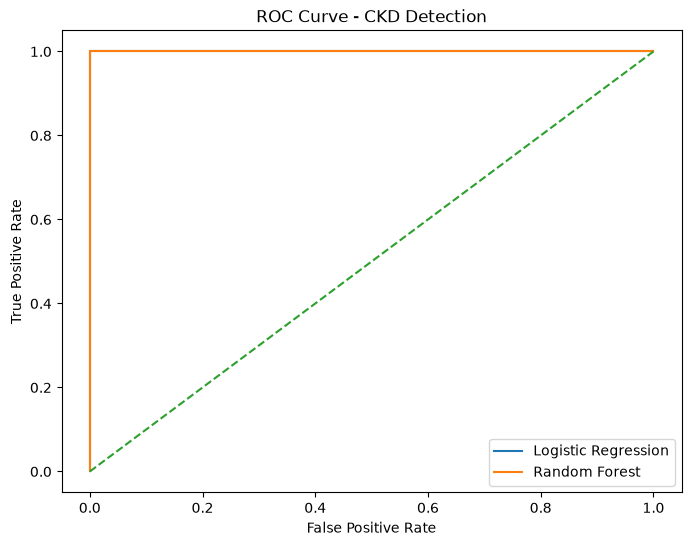

In [88]:
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(8, 6))

plt.plot(fpr_lr, tpr_lr, label='Logistic Regression')

plt.plot(fpr_rf, tpr_rf, label='Random Forest')

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curve - CKD Detection')

plt.legend()
plt.show()

# final model saving - logistic regression : 

In [90]:
import joblib

In [91]:
joblib.dump(model_lr,"lr_model_ckd.pkl")
joblib.dump(scaler,"scaler.pkl")
joblib.dump(X.columns.tolist(),"columns.pkl")

['columns.pkl']